Study the objectives for different attack objectives, L2 and cos distance.

In [1]:
import sys
import os

# Manually specify the path to your project folder
project_path = os.path.abspath('..')  # Or provide the full path if needed
sys.path.append(project_path)

# Now you can import from the sibling folder
from utilities import *
from helper import *

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as T

import torchvision.datasets as datasets
from torch.utils.data import DataLoader
from models import *
import random
from collections import Counter
from collections import OrderedDict
import seaborn as sns
from copy import deepcopy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from collections import Counter

cos = nn.CosineSimilarity(dim=0, eps=1e-9) 
device = "cuda:1"

# study 1 model's training with the new loss function with dist limits

# adjustable parameters
# alpha_d = 100 # IID
iters = 40
learning_rate = 0.001

global attack 
attack = "untargeted" #"backdoor", "tlp", "ut"
model_name = "VGG13" # "ResNet18", "ConvNet"， "VGG13"
num_classes = 10
dataset ="cifar10" # "cifar10", "fmnist", "mnist"

/home2/liyang/micromamba/envs/fl39/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


conv1.weight
bn1.weight
bn1.bias
layer1.0.conv1.weight
layer1.0.bn1.weight
layer1.0.bn1.bias
layer1.0.conv2.weight
layer1.0.bn2.weight
layer1.0.bn2.bias
layer1.1.conv1.weight
layer1.1.bn1.weight
layer1.1.bn1.bias
layer1.1.conv2.weight
layer1.1.bn2.weight
layer1.1.bn2.bias
layer2.0.conv1.weight
layer2.0.bn1.weight
layer2.0.bn1.bias
layer2.0.conv2.weight
layer2.0.bn2.weight
layer2.0.bn2.bias
layer2.0.shortcut.0.weight
layer2.0.shortcut.1.weight
layer2.0.shortcut.1.bias
layer2.1.conv1.weight
layer2.1.bn1.weight
layer2.1.bn1.bias
layer2.1.conv2.weight
layer2.1.bn2.weight
layer2.1.bn2.bias
layer3.0.conv1.weight
layer3.0.bn1.weight
layer3.0.bn1.bias
layer3.0.conv2.weight
layer3.0.bn2.weight
layer3.0.bn2.bias
layer3.0.shortcut.0.weight
layer3.0.shortcut.1.weight
layer3.0.shortcut.1.bias
layer3.1.conv1.weight
layer3.1.bn1.weight
layer3.1.bn1.bias
layer3.1.conv2.weight
layer3.1.bn2.weight
layer3.1.bn2.bias
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.

In [2]:
# Define transformation (convert images to tensors and normalize)
transform_img = T.Compose([
    T.ToTensor(),  # Convert image to tensor
    T.Normalize((0.5,), (0.5,))  # Normalize the image with mean and std
])

if dataset == "mnist":
    train_data = datasets.MNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.MNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "fmnist":
    train_data = datasets.FashionMNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.FashionMNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "cifar10":
    train_data = datasets.CIFAR10(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.CIFAR10(root=f'{project_path}/data', train=False, download=True, transform=transform_img)

Files already downloaded and verified
Files already downloaded and verified


In [3]:
# Create DataLoader for batch processing
fl_data_dict, labels_per_client_dict, label_count_per_client_dict =\
    create_data_fl_clients(client_num=100,
                           noniid_type="dirichlet",
                           label_skew_alpha =None,
                           p_degree=None,
                           dirichlet_alpha=100,
                           fl_train=train_data,
                           fl_class_num=10)

# Combine datasets from clients 0 to 9
combined_dataset = ConcatDataset([fl_data_dict[i] for i in range(10)])
  
# Create a DataLoader for the combined dataset
train_loader = DataLoader(combined_dataset, batch_size=32, shuffle=True, num_workers=1)

In [4]:
# Collect all labels from the combined dataset
all_labels = [label for _, label in combined_dataset]

# Count the occurrences of each label
label_counts = Counter(all_labels)

# Optionally, print the counts in order
for label in range(10):  # assuming 10 classes
    print(f"Label {label}: {label_counts[label]}")

Label 0: 519
Label 1: 482
Label 2: 490
Label 3: 499
Label 4: 524
Label 5: 505
Label 6: 481
Label 7: 491
Label 8: 483
Label 9: 499


In [ ]:
model_class = get_model(model_name)    
model_fn = partial(model_class, num_classes=num_classes)
# model0
model0 = model_fn().to(device)
model0_sd = deepcopy(model0.state_dict())
optimizer0 = optim.SGD(model0.parameters(), lr=learning_rate)
c_criterion0 = nn.CrossEntropyLoss()

# modelt 
modelt = model_fn().to(device)
modelt.load_state_dict(model0_sd)
optimizer1 = optim.SGD(modelt.parameters(), lr=learning_rate)
c_criterion1 = nn.CrossEntropyLoss()

In [6]:
# Helper: clone model parameters
def clone_model_params(model):
    return {name: param.detach().clone() for name, param in model.state_dict().items()}

# Helper: compute model update
def compute_model_update(current_state, previous_state):
    return {name: (current_state[name] - previous_state[name]).detach() for name in current_state}

In [7]:
# Initialize
model_updates = {}  # store updates like {1: g_1, 2: g_2, ...}
prev_model_state = clone_model_params(model0)
accuracy_list =[]

# Normal training to converge
for iter in range(iters):
    train_c_model(train_loader, model0, c_criterion0, optimizer0, attack_method='none', client_id=0,
                  malicious_client_ids=[], optimizer_poison=None, dba_poisoning_per_batch=0.2, device=device)

    # Compute model update
    current_model_state = clone_model_params(model0)
    model_updates[iter + 1] = compute_model_update(current_model_state, prev_model_state)
    prev_model_state = current_model_state  # update for next iteration

    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(model0, c_criterion0, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
    accuracy_list.append(accuracy)
    print(f"iter:{iter}, accuracy:{accuracy}")

iter:0, accuracy:0.253
iter:1, accuracy:0.3146
iter:2, accuracy:0.3621
iter:3, accuracy:0.3978
iter:4, accuracy:0.4512
iter:5, accuracy:0.4319
iter:6, accuracy:0.4804
iter:7, accuracy:0.4936
iter:8, accuracy:0.4944
iter:9, accuracy:0.4739
iter:10, accuracy:0.4952
iter:11, accuracy:0.4948
iter:12, accuracy:0.5034
iter:13, accuracy:0.524
iter:14, accuracy:0.5026
iter:15, accuracy:0.5092
iter:16, accuracy:0.5034
iter:17, accuracy:0.4496
iter:18, accuracy:0.3077
iter:19, accuracy:0.5035
iter:20, accuracy:0.5285
iter:21, accuracy:0.4884
iter:22, accuracy:0.3775
iter:23, accuracy:0.5258
iter:24, accuracy:0.4793
iter:25, accuracy:0.5362
iter:26, accuracy:0.4907
iter:27, accuracy:0.5418
iter:28, accuracy:0.5235


OutOfMemoryError: CUDA out of memory. Tried to allocate 392.00 MiB. GPU 1 has a total capacity of 23.67 GiB of which 211.56 MiB is free. Process 3721800 has 6.22 GiB memory in use. Including non-PyTorch memory, this process has 17.23 GiB memory in use. Of the allocated memory 16.91 GiB is allocated by PyTorch, and 70.54 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
# Flatten a model update (dict of tensors) into a single 1D tensor
def flatten_update(update_dict, device='cpu'):
    # Move tensors to CPU before concatenation to save GPU memory
    return torch.cat([v.view(-1).to(device) for v in update_dict.values()])

# Step 1: Compute flattened updates on CPU
flattened_updates = []
for i in sorted(model_updates):
    # Process one update at a time and move to CPU
    flat_update = flatten_update(model_updates[i], device='cpu').detach()
    flattened_updates.append(flat_update)
    del flat_update  # Explicit cleanup
    torch.cuda.empty_cache()  # Clear unused GPU memory

# Step 2: Compute L2 norms (still on CPU)
l2_norms = [u.norm().item() for u in flattened_updates]

# Initialize matrices
cos_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))
l2_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))

for i in range(len(flattened_updates)):
    print("i:", i)
    # Keep diagonal elements (i==j) which are always 0 for cos_diff and 0 for l2_diff
    cos_diff_matrix[i, i] = 0
    l2_diff_matrix[i, i] = 0
    
    # Only compute upper triangular part (since matrices are symmetric)
    for j in range(i+1, len(flattened_updates)):
        # Move only the needed pair to GPU
        vec_i = flattened_updates[i].to(device)
        vec_j = flattened_updates[j].to(device)
        
        # Compute both metrics at once
        cos_sim = F.cosine_similarity(vec_i.unsqueeze(0), vec_j.unsqueeze(0)).item()
        l2_diff = torch.norm(vec_i - vec_j).item()
        
        # Fill both halves of symmetric matrices
        cos_diff_matrix[i, j] = 1 - cos_sim
        cos_diff_matrix[j, i] = 1 - cos_sim
        l2_diff_matrix[i, j] = l2_diff
        l2_diff_matrix[j, i] = l2_diff
        
        # Clean up
        del vec_i, vec_j
        torch.cuda.empty_cache()

i: 0
i: 1
i: 2
i: 3
i: 4
i: 5
i: 6
i: 7
i: 8
i: 9
i: 10
i: 11
i: 12
i: 13
i: 14
i: 15
i: 16
i: 17
i: 18
i: 19
i: 20
i: 21
i: 22
i: 23
i: 24
i: 25
i: 26
i: 27
i: 28
i: 29
i: 30
i: 31
i: 32
i: 33
i: 34
i: 35
i: 36
i: 37
i: 38
i: 39


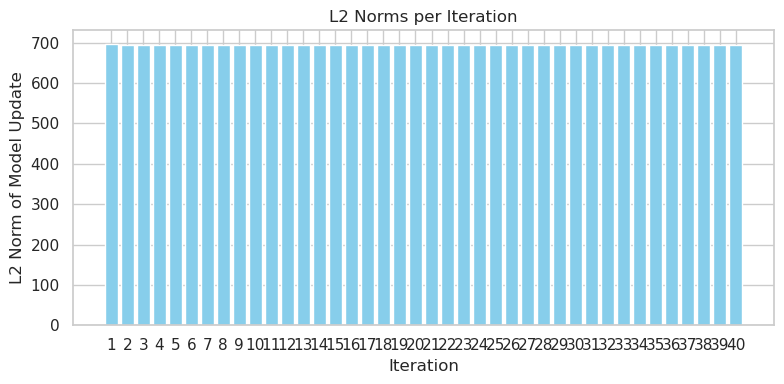

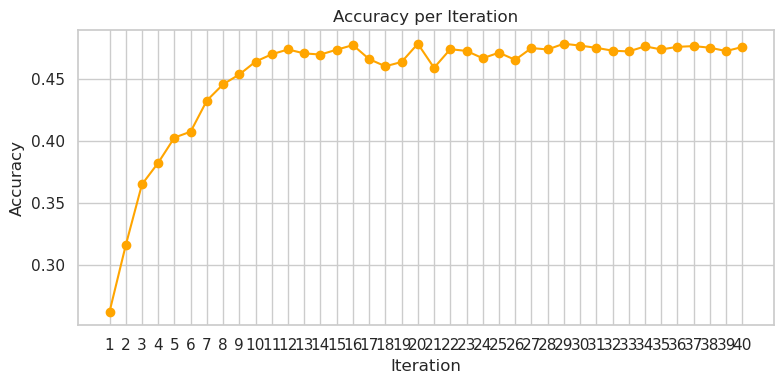

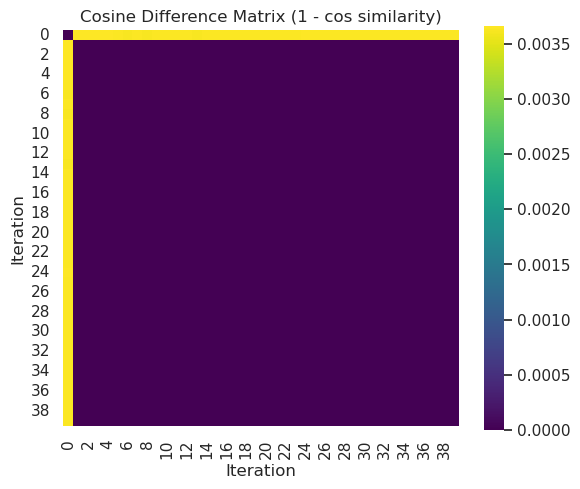

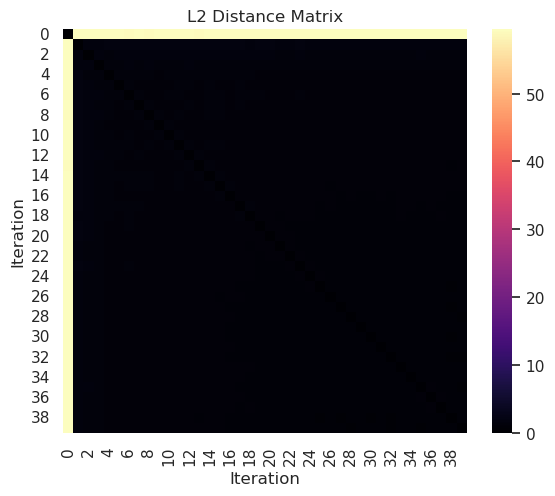

In [ ]:
# Ensure seaborn styling
sns.set(style="whitegrid")

# Plot 1: Bar plot of L2 norms
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(l2_norms) + 1), l2_norms, color='skyblue')
plt.xlabel("Iteration")
plt.ylabel("L2 Norm of Model Update")
plt.title("L2 Norms per Iteration")
plt.xticks(range(1, len(l2_norms) + 1))
plt.tight_layout()
plt.show()

# Plot 2: Line plot of Accuracy per Iteration
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(accuracy_list) + 1), accuracy_list, color='orange', marker='o')
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Accuracy per Iteration")
plt.xticks(range(1, len(accuracy_list) + 1))
plt.grid(True)  # Optional: adds grid lines for better readability
plt.tight_layout()
plt.show()


# Convert matrices to numpy
cos_diff_np = cos_diff_matrix.numpy()
l2_diff_np = l2_diff_matrix.numpy()

# Plot 3: Heatmap of cosine differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(cos_diff_np, annot=False, cmap="viridis", square=True)
plt.title("Cosine Difference Matrix (1 - cos similarity)")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()

# Plot 4: Heatmap of L2 differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(l2_diff_np, annot=False, cmap="magma", square=True)
plt.title("L2 Distance Matrix")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()



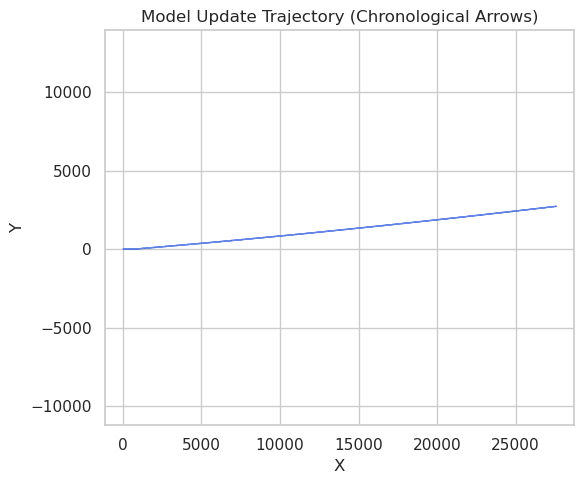

In [ ]:
# plot the trajectory of model updates in 2D space

# Step 1: Flatten updates (if not already done)
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]

# Step 2: Get L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Step 3: Compute angles between successive updates
angles = [0.0]  # start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = F.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    # Determine rotation direction using sign of cross product
    sign = torch.sign(torch.dot(u_prev, u_curr))  # crude check
    if sign < 0:
        angle_diff = -angle_diff
    angles.append(angle_diff)

# Step 4: Convert to absolute angles
absolute_angles = [0.0]
for i in range(1, len(angles)):
    absolute_angles.append(absolute_angles[-1] + angles[i])

# Step 5: Compute vector endpoints
x, y = [0], [0]
for i in range(len(l2_norms)):
    dx = l2_norms[i] * np.cos(absolute_angles[i])
    dy = l2_norms[i] * np.sin(absolute_angles[i])
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)

# Step 6: Plot
plt.figure(figsize=(6, 5))
for i in range(len(l2_norms)):
    plt.arrow(x[i], y[i], x[i+1]-x[i], y[i+1]-y[i],
              head_width=0.05*max(l2_norms), length_includes_head=True,
              color='royalblue', alpha=0.8)

plt.title("Model Update Trajectory (Chronological Arrows)")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


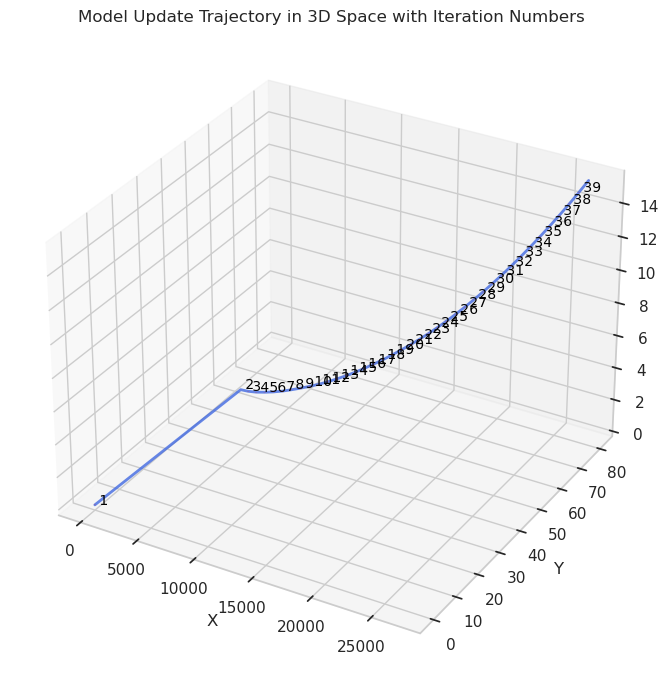

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from mpl_toolkits.mplot3d import Axes3D

# Assuming model_updates is a dictionary or list with flattened model updates
# You would replace the below code with your actual model update data.
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]  # Flatten updates

# Calculate L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Compute angles between consecutive updates (using cosine similarity)
angles = [0.0]  # Start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = torch.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    angles.append(angle_diff)

# Compute 3D coordinates of the trajectory
x, y, z = [0], [0], [0]

# For simplicity, assume updates occur in 3D space
for i in range(1, len(l2_norms)):
    dx = l2_norms[i] * np.cos(angles[i])  # X direction
    dy = l2_norms[i] * np.sin(angles[i])  # Y direction
    dz = i * 0.02  # Slightly separate updates in the Z direction for clarity
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)
    z.append(z[-1] + dz)

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot the 3D trajectory path as a line
ax.plot(x, y, z, color='royalblue', alpha=0.8, linewidth=2)

# Plot arrows for each update
for i in range(len(l2_norms) - 1):
    ax.quiver(x[i], y[i], z[i], x[i+1] - x[i], y[i+1] - y[i], z[i+1] - z[i],
              length=0.1, normalize=True, color='red', alpha=0.6)

    # Add iteration number as a label near the arrows
    ax.text(x[i] + 0.02, y[i] + 0.02, z[i] + 0.02, f" {i+1}", color='black', fontsize=10)

# Labels and title
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title("Model Update Trajectory in 3D Space with Iteration Numbers")

# Display the plot
plt.tight_layout()
plt.show()


# Attack with budget on L2 norm


In [ ]:
# copy the trained model0 to modelt
modelt.load_state_dict(model0.state_dict())

# test the modelt
test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(modelt, c_criterion1, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
print(f"modelt accuracy:{accuracy}")

modelt accuracy:0.4755


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms


# Assuming `modelt` is your pre-trained model on Fashion-MNIST
# Assuming `train_loader` and `val_loader` are DataLoaders for your training and validation data

class NegativeCrossEntropyLoss(nn.Module):
    def __init__(self):
        super(NegativeCrossEntropyLoss, self).__init__()
        self.ce_loss = nn.CrossEntropyLoss()

    def forward(self, outputs, labels):
        return -self.ce_loss(outputs, labels)

def train_one_epoch_with_negative_ce(model, train_loader, device):
    model.train()
    neg_ce_loss = NegativeCrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001)  # Adjust learning rate if needed

    # Save a copy of the original model parameters
    original_state = deepcopy(model.state_dict())

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = neg_ce_loss(outputs, labels)
        
        loss.backward()
        optimizer.step()
    
    # Calculate G_m as the difference between the new and original model parameters
    G_m = {name: model.state_dict()[name] - original_state[name] for name in model.state_dict()}
    model.load_state_dict(original_state)  # Restore original model parameters
    return G_m

def calculate_average_l2_norm(l2_norms):
    return sum(l2_norms) / len(l2_norms)

def calculate_l2_distance(original_weights, attacked_weights):
    """Calculate the L2 distance between two sets of weights."""
    return torch.norm(attacked_weights - original_weights).item()



def apply_attack(model, G_m, average_l2_norm, magnitudes):
    # Calculate total L2 norm of G_m
    total_norm = torch.sqrt(sum((g.float().norm() ** 2 for g in G_m.values())))
    print("G_m norm", total_norm)

    # Compute scaling factor
    multi = average_l2_norm / total_norm
    print("multi", multi)

    # Scale G_m
    normalized_G_m = {name: g.float() * multi for name, g in G_m.items()}
    total_norm_normalized = torch.sqrt(sum((g.norm() ** 2 for g in normalized_G_m.values())))
    print("total_norm_normalized", total_norm_normalized)

    attacked_models = []
    l2_distances = []

    # Flatten original model parameters for distance comparison
    original_params = flatten_model(model.state_dict())

    for magnitude in magnitudes:
        # Create a copy of the original model
        malicious_model = copy.deepcopy(model)

        # Apply attack to parameters and float-type buffers
        with torch.no_grad():
            for name, param in malicious_model.named_parameters():
                if name in normalized_G_m:
                    param.add_(normalized_G_m[name] * magnitude)
            for name, buffer in malicious_model.named_buffers():
                if name in normalized_G_m and torch.is_floating_point(buffer):
                    buffer.add_(normalized_G_m[name] * magnitude)

        # Add the model to the list
        attacked_models.append(malicious_model)

        # Compute L2 distance
        malicious_params = flatten_model(malicious_model.state_dict())
        distance = torch.norm(original_params - malicious_params, p=2)
        l2_distances.append(distance.item())

    return attacked_models, l2_distances



def evaluate_model(model, val_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

def flatten_model(state_dict):
    """Flatten a model's state_dict into a single 1D tensor."""
    return torch.cat([param.flatten() for param in state_dict.values()])

modelt = modelt.to(device)

# Assuming `l2_norms` is the list of L2 norms recorded during benign training
average_l2_norm = calculate_average_l2_norm(l2_norms)
print(f"Average L2 Norm: {average_l2_norm}")

# Calculate G_m
G_m = train_one_epoch_with_negative_ce(modelt, train_loader, device)
print("G_m norm", torch.norm(flatten_model(G_m)))

# Define magnitudes
magnitudes = [x * 0.25 for x in range(0, 9)] + list(range(2, 31))

# Apply attack and create malicious models
attacked_models, l2_distances = apply_attack(modelt, G_m, average_l2_norm, magnitudes)
attack_accuracy_list = []

print(len(attacked_models))

# Evaluate each malicious model
for i, attackeG_model in enumerate(attacked_models):
    print(i)
    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(attackeG_model, c_criterion1, 
                        test_data, server_batch_size=32, class_num=10, attack_method='none',
                        mali_labels=[0,7], device=device)
    
    attack_accuracy_list.append(accuracy*100)
    print(f'Malicious Model {i} with magnitudes {magnitudes[i]}: Accuracy = {accuracy * 100:.2f}')


Average L2 Norm: 693.2444839477539
G_m norm tensor(693.9100, device='cuda:1')
G_m norm tensor(693.9100, device='cuda:1')
multi tensor(0.9990, device='cuda:1')
total_norm_normalized tensor(693.2444, device='cuda:1')
38
0
Malicious Model 0 with magnitudes 0.0: Accuracy = 47.55
1
Malicious Model 1 with magnitudes 0.25: Accuracy = 9.49
2
Malicious Model 2 with magnitudes 0.5: Accuracy = 3.60
3
Malicious Model 3 with magnitudes 0.75: Accuracy = 2.92
4
Malicious Model 4 with magnitudes 1.0: Accuracy = 3.28
5
Malicious Model 5 with magnitudes 1.25: Accuracy = 3.70
6
Malicious Model 6 with magnitudes 1.5: Accuracy = 4.12
7
Malicious Model 7 with magnitudes 1.75: Accuracy = 10.00
8
Malicious Model 8 with magnitudes 2.0: Accuracy = 10.00
9
Malicious Model 9 with magnitudes 2: Accuracy = 10.00
10
Malicious Model 10 with magnitudes 3: Accuracy = 10.00
11
Malicious Model 11 with magnitudes 4: Accuracy = 10.00
12
Malicious Model 12 with magnitudes 5: Accuracy = 10.00
13
Malicious Model 13 with magni

In [ ]:
attack_accuracy_list

[47.55,
 9.49,
 3.5999999999999996,
 2.92,
 3.2800000000000002,
 3.6999999999999997,
 4.12,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0,
 10.0]

In [ ]:
max_att_index = min(enumerate(attack_accuracy_list), key=lambda x: x[1])[0]
max_attack_l2_dist = l2_distances[max_att_index]

l2_distances

[0.0,
 7.941772937774658,
 15.883545875549316,
 23.825319290161133,
 31.767091751098633,
 39.708866119384766,
 47.650638580322266,
 55.59241485595703,
 63.534183502197266,
 63.534183502197266,
 95.30127716064453,
 127.06836700439453,
 158.83546447753906,
 190.60255432128906,
 222.36965942382812,
 254.13673400878906,
 285.9038391113281,
 317.6709289550781,
 349.4380187988281,
 381.2051086425781,
 412.9721984863281,
 444.73931884765625,
 476.50634765625,
 508.2734680175781,
 540.0405883789062,
 571.8076782226562,
 603.5747680664062,
 635.3418579101562,
 667.1089477539062,
 698.8760375976562,
 730.6431884765625,
 762.4102172851562,
 794.1773071289062,
 825.9443969726562,
 857.7114868164062,
 889.4786376953125,
 921.2456665039062,
 953.0126953125]

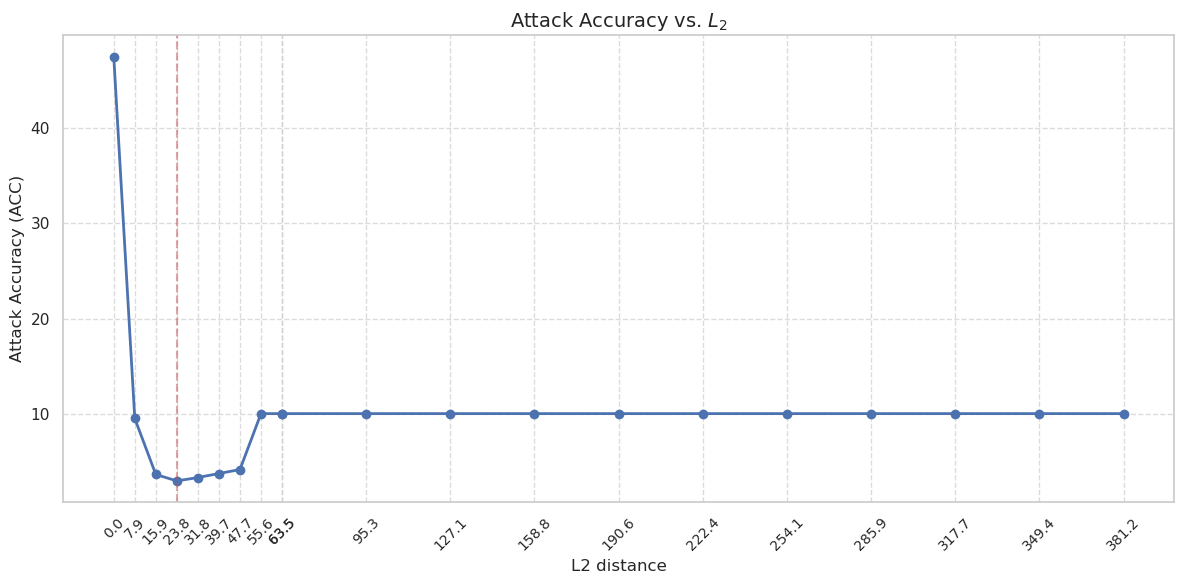

In [ ]:
# Create the plot
plt.figure(figsize=(12, 6))
plt.plot(l2_distances[:20], attack_accuracy_list[:20], marker='o', linestyle='-', color='b', linewidth=2)

# Customize the plot
plt.title('Attack Accuracy vs. $L_2$', fontsize=14)
plt.xlabel('L2 distance', fontsize=12)
plt.ylabel('Attack Accuracy (ACC)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Set x-axis ticks: 
# - Show all 0.1 steps from 0.0 to 1.0
# - Then show 1.0 steps from 1.0 to max magnitude
# max_magnitude = max(magnitudes)
# xticks = magnitudes
max_l2 = max(l2_distances)
xticks = l2_distances[:20]
plt.xticks(xticks, fontsize=10)

# Rotate x-axis labels for better readability if many ticks
plt.xticks(rotation=45)

# Add a vertical line at magnitude=1 to mark the transition
plt.axvline(x=max_attack_l2_dist, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
# Flatten the models
original_flat = flatten_model(model0_sd)
benign_flat = flatten_model(modelt.state_dict())
attacked_flat = flatten_model(attacked_models[max_att_index].state_dict())

models = [original_flat, benign_flat, attacked_flat]
model_names = ["Original", "Benign", "Attacked"]

In [ ]:
l2_diff_matrix = torch.zeros(3, 3)
for i in range(3):
    for j in range(3):
        l2_diff_matrix[i, j] = torch.norm(models[i] - models[j]).item()

print("\nL2 Distance Matrix:")
print(l2_diff_matrix)


L2 Distance Matrix:
tensor([[0.0000e+00, 2.7727e+04, 2.7727e+04],
        [2.7727e+04, 0.0000e+00, 2.3825e+01],
        [2.7727e+04, 2.3825e+01, 0.0000e+00]])


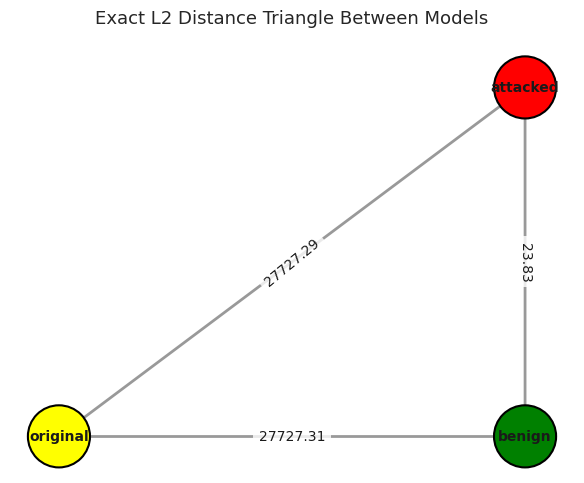

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx
import torch
import math

# Distance matrix
l2_matrix = l2_diff_matrix

# Model names
model_names = ['original', 'benign', 'attacked']
model_types = {'original': 'original', 'benign': 'benign', 'attacked': 'attacked'}
color_map = {'original': 'yellow', 'benign': 'green', 'attacked': 'red'}

# Assign positions based on triangle geometry
a = l2_matrix[0, 1].item()  # AB
b = l2_matrix[0, 2].item()  # AC
c = l2_matrix[1, 2].item()  # BC

# Fix A at (0, 0), B at (a, 0), find C
# Use cosine law to get angle at A
cos_CAB = (a**2 + b**2 - c**2) / (2 * a * b)
angle_CAB = math.acos(cos_CAB)

# Coordinates
pos = {
    'original': (0, 0),
    'benign': (a, 0),
    'attacked': (b * math.cos(angle_CAB), b * math.sin(angle_CAB))
}

# Create graph
G = nx.Graph()
for name in model_names:
    G.add_node(name)

# Add edges with L2 distances
for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        G.add_edge(model_names[i], model_names[j], weight=round(l2_matrix[i, j].item(), 2))

# Draw
node_colors = [color_map[model_types[name]] for name in model_names]
plt.figure(figsize=(6, 5))
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color=node_colors, edgecolors='black', linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
nx.draw_networkx_edges(G, pos, width=2, edge_color='gray', alpha=0.8)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels, font_size=10,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8)
)

plt.title("Exact L2 Distance Triangle Between Models", pad=20, fontsize=13)
plt.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
# for each layer we test the sensitivity in regards of the attack

def apply_attack_to_specific_layer(model, G_m, l2_budget, layer_name):
    # Calculate the total L2 norm of the gradient update for normalization
    total_norm = torch.sqrt(sum((g_m.norm() ** 2 for g_m in G_m.values())))
    normalized_G_m = {name: g_m * (l2_budget / total_norm) for name, g_m in G_m.items()}

    new_model = deepcopy(model)
    for name, param in new_model.named_parameters():
        if name == layer_name:
            # Calculate the current L2 norm of the specific layer's update
            current_layer_norm = normalized_G_m[name].norm()
            
            # Calculate the magnitude needed to achieve the specified L2 budget
            if current_layer_norm != 0:
                magnitude = l2_budget / current_layer_norm
            else:
                magnitude = 0  # Avoid division by zero
            
            # Apply the calculated magnitude to achieve the L2 budget
            param.data += magnitude * normalized_G_m[name]

    return new_model


def apply_attack_to_all_layers(model, G_m, l2_budget):
    # Convert all gradients to float and compute total L2 norm
    total_norm = torch.sqrt(sum((g_m.float().norm() ** 2 for g_m in G_m.values())))
    
    # Avoid division by zero
    if total_norm == 0:
        return model
    
    # Compute scaling factor
    scale = min(1.0, l2_budget / total_norm)
    print("scale", scale)
    
    # Apply scaled attack to each layer
    attacked_model = copy.deepcopy(model)
    with torch.no_grad():
        for name, param in attacked_model.named_parameters():
            if name in G_m:
                # Ensure both parameter and gradient are float
                param.data += scale * G_m[name].float().to(param.device)
    
    return attacked_model


def evaluate_and_record_sensitivities(model, G_m, max_l2, num_records, test_data, device):
    # Convert gradients to float upfront
    G_m = {name: g_m.float() for name, g_m in G_m.items()}
    
    layer_names = [name for name, _ in model.named_parameters()]
    # Create a sequence of L2 distances
    l2_dists = np.linspace(0, max_l2, num_records)
    results_matrix = np.zeros((len(layer_names), len(l2_dists)))
    print("layer_names", layer_names)
    
    for layer_index, layer_name in enumerate(layer_names):
        print(f"Evaluating layer: {layer_name}")
        for idx, l2_budget in enumerate(l2_dists):
            attacked_model = apply_attack_to_specific_layer(model, G_m, l2_budget, layer_name)
            test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(
                attacked_model, c_criterion1, test_data, server_batch_size=32, class_num=10,
                attack_method='none', mali_labels=[0, 7], device=device
            )
            results_matrix[layer_index, idx] = accuracy
            print(f"Layer: {layer_name}, L2 Budget: {l2_budget:.2f}, Accuracy: {accuracy:.4f}")

    return results_matrix, layer_names, l2_dists


def evaluate_attack_on_all_layers(model, G_m, max_l2, num_records, test_data, device):
    # Create a sequence of L2 distances
    l2_dists = np.linspace(0, max_l2, num_records)
    results_list = []
    
    # Convert all gradients in G_m to float upfront
    G_m = {k: v.float() for k, v in G_m.items()}
    
    for l2_budget in l2_dists:
        print(f"Evaluating attack with total L2 budget: {l2_budget}")
        attacked_model = apply_attack_to_all_layers(model, G_m, l2_budget)
        test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(
            attacked_model, c_criterion1, test_data, server_batch_size=32, class_num=10,
            attack_method='none', mali_labels=[0, 7], device=device
        )
        results_list.append(accuracy)
        print(f"L2 Budget: {l2_budget}, Accuracy: {accuracy}")

    return np.array(results_list), l2_dists



def plot_sensitivity_matrix(results_matrix, layer_names, L2_dists):
    plt.figure(figsize=(12, 6))
    im = plt.imshow(results_matrix, aspect='auto', cmap='viridis', origin='lower')

    # Get min and max values from the matrix
    vmin = results_matrix.min()
    vmax = results_matrix.max()

    # Create colorbar with ticks at 0.1 intervals between min and max
    ticks = np.arange(vmin, vmax + 0.1, 0.1)
    ticks = np.clip(ticks, vmin, vmax)  # Ensure ticks don't go beyond min and max

    cbar = plt.colorbar(im, ticks=ticks)
    cbar.ax.set_yticklabels([f"{tick:.2f}" for tick in ticks])
    cbar.set_label('Accuracy')

    plt.xlabel('L2 Distance')
    plt.ylabel('Layer Index')

    # Tick positions: every 2nd plus the last if not already included
    tick_indices = list(np.arange(0, len(L2_dists), 1))
    if (len(L2_dists) - 1) not in tick_indices:
        tick_indices.append(len(L2_dists) - 1)

    formatted_xticks = [f"{L2_dists[i]:.4f}" for i in tick_indices]
    plt.xticks(ticks=tick_indices, labels=formatted_xticks, rotation=45)

    plt.yticks(ticks=np.arange(len(layer_names)), labels=layer_names)
    plt.gca().invert_yaxis()

    plt.title('Sensitivity Analysis of Layers to Attack')
    plt.tight_layout()
    plt.show()


In [ ]:
# Evaluate and record sensitivities
results_matrix, layer_names, l2_distances = evaluate_and_record_sensitivities(
    modelt, G_m, max_attack_l2_dist, 20, test_data, device
)

layer_names ['conv1.weight', 'bn1.weight', 'bn1.bias', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.bn1.bias', 'layer1.1.conv2.weight', 'layer1.1.bn2.weight', 'layer1.1.bn2.bias', 'layer2.0.conv1.weight', 'layer2.0.bn1.weight', 'layer2.0.bn1.bias', 'layer2.0.conv2.weight', 'layer2.0.bn2.weight', 'layer2.0.bn2.bias', 'layer2.0.shortcut.0.weight', 'layer2.0.shortcut.1.weight', 'layer2.0.shortcut.1.bias', 'layer2.1.conv1.weight', 'layer2.1.bn1.weight', 'layer2.1.bn1.bias', 'layer2.1.conv2.weight', 'layer2.1.bn2.weight', 'layer2.1.bn2.bias', 'layer3.0.conv1.weight', 'layer3.0.bn1.weight', 'layer3.0.bn1.bias', 'layer3.0.conv2.weight', 'layer3.0.bn2.weight', 'layer3.0.bn2.bias', 'layer3.0.shortcut.0.weight', 'layer3.0.shortcut.1.weight', 'layer3.0.shortcut.1.bias', 'layer3.1.conv1.weight', 'layer3.1.bn1.weight', 'layer3.1.bn1.bias', 'layer3.1.

In [ ]:
max_attack_l2_dist

23.825319290161133

In [ ]:
results_list_all, l2_dists_all = evaluate_attack_on_all_layers(modelt, G_m, max_attack_l2_dist, 20, test_data, device)

Evaluating attack with total L2 budget: 0.0
scale tensor(0., device='cuda:1')


L2 Budget: 0.0, Accuracy: 0.4755
Evaluating attack with total L2 budget: 1.2539641731663753
scale tensor(0.0018, device='cuda:1')
L2 Budget: 1.2539641731663753, Accuracy: 0.4747
Evaluating attack with total L2 budget: 2.5079283463327506
scale tensor(0.0036, device='cuda:1')
L2 Budget: 2.5079283463327506, Accuracy: 0.473
Evaluating attack with total L2 budget: 3.761892519499126
scale tensor(0.0054, device='cuda:1')
L2 Budget: 3.761892519499126, Accuracy: 0.4729
Evaluating attack with total L2 budget: 5.015856692665501
scale tensor(0.0072, device='cuda:1')
L2 Budget: 5.015856692665501, Accuracy: 0.4708
Evaluating attack with total L2 budget: 6.269820865831877
scale tensor(0.0090, device='cuda:1')
L2 Budget: 6.269820865831877, Accuracy: 0.4691
Evaluating attack with total L2 budget: 7.523785038998252
scale tensor(0.0108, device='cuda:1')
L2 Budget: 7.523785038998252, Accuracy: 0.4686
Evaluating attack with total L2 budget: 8.777749212164627
scale tensor(0.0126, device='cuda:1')
L2 Budget:

In [ ]:
results_list_all, l2_dists_all

(array([0.4755, 0.4747, 0.473 , 0.4729, 0.4708, 0.4691, 0.4686, 0.4664,
        0.463 , 0.4602, 0.4556, 0.4527, 0.4493, 0.447 , 0.4444, 0.4391,
        0.4342, 0.4281, 0.424 , 0.4195]),
 array([ 0.        ,  1.25396417,  2.50792835,  3.76189252,  5.01585669,
         6.26982087,  7.52378504,  8.77774921, 10.03171339, 11.28567756,
        12.53964173, 13.7936059 , 15.04757008, 16.30153425, 17.55549842,
        18.8094626 , 20.06342677, 21.31739094, 22.57135512, 23.82531929]))

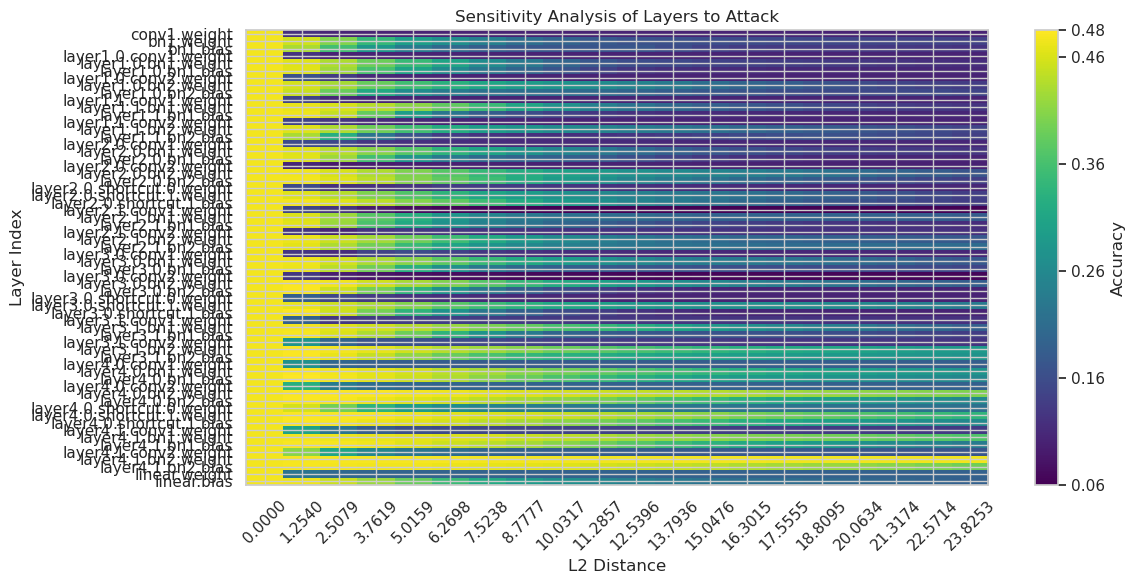

In [ ]:
# Plot the sensitivity matrix
plot_sensitivity_matrix(results_matrix, layer_names, l2_dists_all)

/tmp/ipykernel_3721800/2977477490.py:66: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for legend


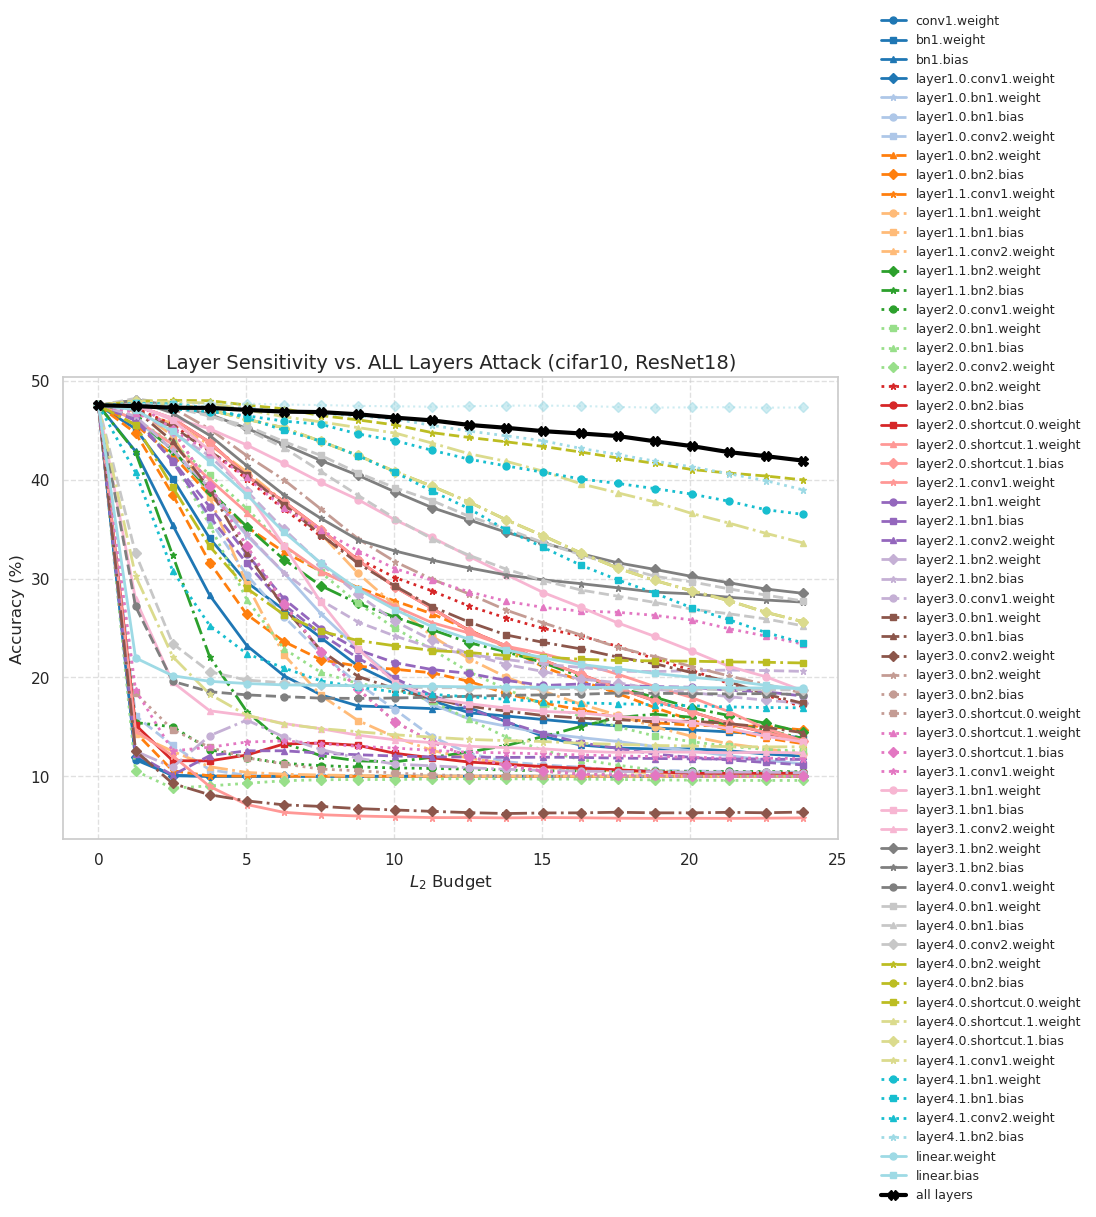

In [ ]:
import itertools

def plot_sensitivity_lines_2(results_matrix, layer_names, L2_dists, results_list_all=None):
    import matplotlib.pyplot as plt
    import numpy as np
    import itertools

    plt.figure(figsize=(10, 6))  # Slightly larger figure to accommodate legend

    # Colors and styles
    line_styles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'D', '*']
    colors = plt.cm.tab20(np.linspace(0, 1, len(layer_names)))
    style_combinations = list(itertools.product(line_styles, markers))

    # Determine dynamic threshold: 80% of the global max accuracy
    max_accuracy = results_matrix.max() * 100  # in percentage
    threshold = 0.9 * max_accuracy

    for idx, (layer_name, color) in enumerate(zip(layer_names, colors)):
        acc_curve = results_matrix[idx] * 100  # Convert to percentage
        min_acc = acc_curve.min()
        line_style, marker = style_combinations[idx % len(style_combinations)]

        if min_acc < threshold:
            label = layer_name
            linewidth = 2
            alpha = 1.0
        else:
            label = None
            linewidth = 1.5
            alpha = 0.5

        plt.plot(
            L2_dists, acc_curve, label=label,
            linestyle=line_style, marker=marker, color=color,
            linewidth=linewidth, markersize=5, alpha=alpha
        )

    # Plot "ALL" line
    if results_list_all is not None:
        plt.plot(
            L2_dists, results_list_all * 100, label="all layers",  # Convert to percentage
            color='black', linestyle='-', linewidth=3,
            marker='X', markersize=7
        )

    # Remove duplicate labels and place legend outside
    handles, labels = plt.gca().get_legend_handles_labels()
    unique = dict(zip(labels, handles))  # Remove duplicates
    
    # Place legend outside to the right of the plot
    plt.legend(
        unique.values(), 
        unique.keys(), 
        loc='center left', 
        bbox_to_anchor=(1.04, 0.5), 
        fontsize=9,
        frameon=False
    )

    plt.xlabel('$L_2$ Budget', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.title(f'Layer Sensitivity vs. ALL Layers Attack ({dataset}, {model_name})', fontsize=14)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for legend
    plt.show()



plot_sensitivity_lines_2(results_matrix, layer_names, l2_dists_all, results_list_all)